# 03 · Customer Segmentation using RFM Analysis
**Project:** Retail Shop Analysis Using Data Analytics

**RFM** is a classic marketing technique. It describes each customer with three numbers:

| Letter | Measure | Question it answers | Better when |
|---|---|---|---|
| **R**ecency | Days since the customer's last order | *How recently did they buy?* | lower |
| **F**requency | Number of distinct orders | *How often do they buy?* | higher |
| **M**onetary | Total amount spent | *How much do they spend?* | higher |

**Method**
1. Calculate R, F and M for each customer.
2. Convert each measure into a **score from 1 to 5** using quintiles (each score holds about
   20% of customers). For Recency the scale is reversed, so a recent buyer gets 5.
3. Assign each customer to a **business segment** using simple, explainable rules on the scores.
4. Profile each segment and recommend an action.

The **reference date** is the day after the last order in the data, 31 Dec 2012. We use it
instead of today's date, because the data ends in 2012.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import viz_style as vs

vs.apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
df = pd.read_csv("../dataset/cleaned_data.csv", parse_dates=["order_date"])
ref_date = df["order_date"].max() + pd.Timedelta(days=1)
print("Reference date:", ref_date.date())

Reference date: 2012-12-31


## Step 1 · Calculate Recency, Frequency and Monetary value

In [2]:
rfm = df.groupby("customer_name").agg(
    last_order=("order_date", "max"),
    first_order=("order_date", "min"),
    frequency=("order_id", "nunique"),
    monetary=("sales", "sum"),
    profit=("profit", "sum"),
)
rfm["recency"] = (ref_date - rfm["last_order"]).dt.days
rfm["tenure_days"] = (ref_date - rfm["first_order"]).dt.days
rfm = rfm[["recency", "frequency", "monetary", "profit", "first_order", "last_order", "tenure_days"]]
print(rfm.shape[0], "customers")
rfm.describe().T

795 customers


,count,mean,min,25%,50%,75%,max,std
recency,795.00,233.87,1.00,69.00,156.00,310.50,"1,431.00",231.35
frequency,795.00,6.94,1.00,4.00,6.00,9.00,26.00,3.75
monetary,795.00,"18,761.76",85.72,"7,364.20","15,287.67","25,401.01","117,124.44","15,973.74"
profit,795.00,"1,914.17","-14,154.29",-99.77,979.54,"3,510.95","34,005.44","4,255.45"
first_order,795,2009-08-11 06:07:41.886792,2009-01-01 00:00:00,2009-03-01 00:00:00,2009-05-29 00:00:00,2009-11-19 00:00:00,2012-05-21 00:00:00,NaN
last_order,795,2012-05-11 03:10:11.320754,2009-01-30 00:00:00,2012-02-24 12:00:00,2012-07-28 00:00:00,2012-10-23 00:00:00,2012-12-30 00:00:00,NaN
tenure_days,795.00,"1,237.74",224.00,"1,138.00","1,312.00","1,401.00","1,460.00",222.70


## Step 2 · Score each measure from 1 to 5 (quintiles)
We rank customers first and then cut the ranks into 5 equal groups. Ranking avoids errors
when many customers share the same value (for example, many customers with 6 orders).

In [3]:
def quintile_score(series, ascending=True):
    """Return 1-5 scores; 5 = best. Ranking first guarantees 5 equal-sized groups."""
    ranks = series.rank(method="first", ascending=ascending)
    return pd.qcut(ranks, 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["R"] = quintile_score(rfm["recency"], ascending=False)   # fewer days -> higher score
rfm["F"] = quintile_score(rfm["frequency"])
rfm["M"] = quintile_score(rfm["monetary"])
rfm["RFM_score"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)
rfm["RFM_total"] = rfm[["R", "F", "M"]].sum(axis=1)

# Show what each score means in real units
score_ranges = pd.concat({
    "Recency (days)": rfm.groupby("R")["recency"].agg(["min", "max"]),
    "Frequency (orders)": rfm.groupby("F")["frequency"].agg(["min", "max"]),
    "Monetary ($)": rfm.groupby("M")["monetary"].agg(["min", "max"]).round(0),
}, axis=1)
score_ranges.index.name = "score"
score_ranges

Recency (days)       Frequency (orders)     Monetary ($)           
                 min   max                min max          min        max
score                                                                    
1                379  1431                  1   4        86.00   6,014.00
2                215   379                  4   5     6,032.00  11,784.00
3                118   214                  5   7    11,813.00  18,807.00
4                 60   117                  7   9    18,834.00  28,599.00
5                  1    60                 10  26    28,774.00 117,124.00

## Step 3 · Assign business segments
The rules are checked **top to bottom**. A customer receives the first segment whose rule
matches, so every customer belongs to exactly one segment.

| # | Segment | Rule | Meaning |
|---|---|---|---|
| 1 | **High-Value (Champions)** | R ≥ 4, F ≥ 4, M ≥ 4 | Bought recently, often and spend the most |
| 2 | **New Customers** | first order in the last 365 days | Recently acquired; still forming a habit |
| 3 | **Loyal Customers** | R ≥ 3, F ≥ 4 | Buy often and are still active |
| 4 | **Potential Loyalists** | R ≥ 3, F 2–3 | Active with moderate frequency; can be grown |
| 5 | **Need Attention** | R ≥ 3, F = 1 | Active but buy rarely |
| 6 | **At-Risk Customers** | R ≤ 2, F ≥ 3 | Used to buy regularly but have not bought for a long time |
| 7 | **Hibernating / Lost** | R ≤ 2, F ≤ 2 | Infrequent and long inactive |

In [4]:
def assign_segment(row):
    R, F, M = row["R"], row["F"], row["M"]
    if R >= 4 and F >= 4 and M >= 4:
        return "High-Value (Champions)"
    if row["tenure_days"] <= 365:
        return "New Customers"
    if R >= 3 and F >= 4:
        return "Loyal Customers"
    if R >= 3 and F >= 2:
        return "Potential Loyalists"
    if R >= 3:
        return "Need Attention"
    if F >= 3:
        return "At-Risk Customers"
    return "Hibernating / Lost"

SEGMENT_ORDER = ["High-Value (Champions)", "Loyal Customers", "Potential Loyalists", "New Customers",
                 "Need Attention", "At-Risk Customers", "Hibernating / Lost"]
rfm["segment"] = pd.Categorical(rfm.apply(assign_segment, axis=1), SEGMENT_ORDER, ordered=True)
rfm["segment"].value_counts().reindex(SEGMENT_ORDER)

segment
High-Value (Champions)    127
Loyal Customers           117
Potential Loyalists       184
New Customers               5
Need Attention             46
At-Risk Customers         133
Hibernating / Lost        183
Name: count, dtype: int64

## Step 4 · Segment profile

In [5]:
total_rev = rfm["monetary"].sum()
profile = rfm.groupby("segment", observed=False).agg(
    customers=("recency", "size"),
    avg_recency_days=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean"),
    total_revenue=("monetary", "sum"),
    total_profit=("profit", "sum"),
)
profile["customer_share_pct"] = profile["customers"] / profile["customers"].sum() * 100
profile["revenue_share_pct"] = profile["total_revenue"] / total_rev * 100
profile["margin_pct"] = profile["total_profit"] / profile["total_revenue"] * 100
profile

,customers,avg_recency_days,avg_frequency,avg_monetary,total_revenue,total_profit,customer_share_pct,revenue_share_pct,margin_pct
segment,,,,,,,,,
High-Value (Champions),127,55.02,12.01,"38,554.49","4,896,419.99","584,146.53",15.97,32.83,11.93
Loyal Customers,117,111.86,9.46,"20,483.81","2,396,605.74","204,897.73",14.72,16.07,8.55
Potential Loyalists,184,101.74,5.55,"15,196.73","2,796,199.14","239,054.58",23.14,18.75,8.55
New Customers,5,139.00,2.60,"15,309.85","76,549.24","4,418.65",0.63,0.51,5.77
Need Attention,46,97.85,3.24,"5,651.40","259,964.62","7,873.97",5.79,1.74,3.03
At-Risk Customers,133,357.06,8.06,"21,028.96","2,796,852.09","289,491.55",16.73,18.75,10.35
Hibernating / Lost,183,516.09,3.44,"9,251.42","1,693,010.01","191,884.97",23.02,11.35,11.33


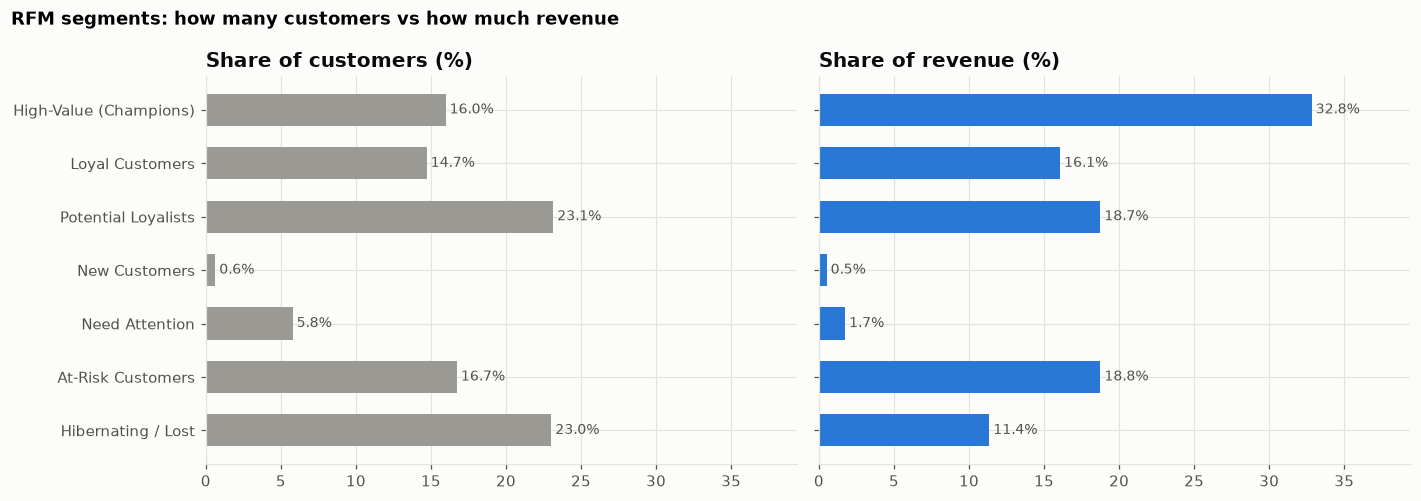

In [6]:
# Customers vs revenue share per segment (two panels, one measure each)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
labels = profile.index[::-1]
axes[0].barh(labels, profile["customer_share_pct"][::-1], color=vs.GRAY, height=0.6)
axes[0].set_title("Share of customers (%)")
axes[1].barh(labels, profile["revenue_share_pct"][::-1], color=vs.BLUE, height=0.6)
axes[1].set_title("Share of revenue (%)")
for ax, col in zip(axes, ["customer_share_pct", "revenue_share_pct"]):
    for y, v in enumerate(profile[col][::-1]):
        ax.text(v, y, f" {v:.1f}%", va="center", fontsize=9, color=vs.TEXT_2)
    ax.set_xlim(0, profile[["customer_share_pct", "revenue_share_pct"]].values.max() * 1.2)
fig.suptitle("RFM segments: how many customers vs how much revenue", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); vs.save(fig, "18_rfm_segment_share.png"); plt.show()

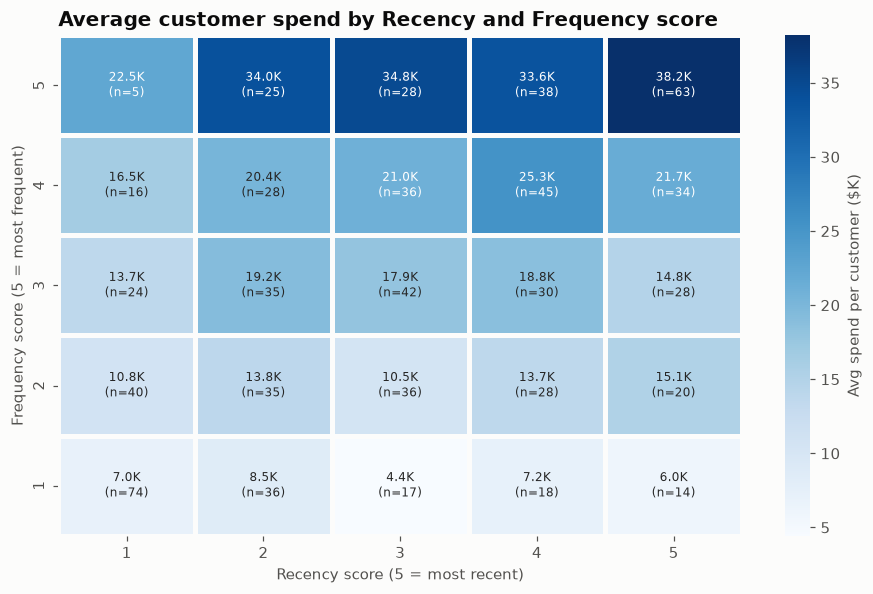

In [7]:
# Average monetary value for each Recency x Frequency score combination
grid = rfm.pivot_table(index="F", columns="R", values="monetary", aggfunc="mean").sort_index(ascending=False)
counts = rfm.pivot_table(index="F", columns="R", values="monetary", aggfunc="size").sort_index(ascending=False)
annot = (grid / 1e3).round(1).astype(str) + "K\n(n=" + counts.fillna(0).astype(int).astype(str) + ")"
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(grid / 1e3, cmap=vs.SEQ_CMAP, annot=annot, fmt="", linewidths=2, linecolor=vs.SURFACE,
            cbar_kws={"label": "Avg spend per customer ($K)"}, ax=ax, annot_kws={"fontsize": 8})
ax.set_xlabel("Recency score (5 = most recent)"); ax.set_ylabel("Frequency score (5 = most frequent)")
ax.set_title("Average customer spend by Recency and Frequency score")
fig.tight_layout(); vs.save(fig, "19_rfm_heatmap.png"); plt.show()

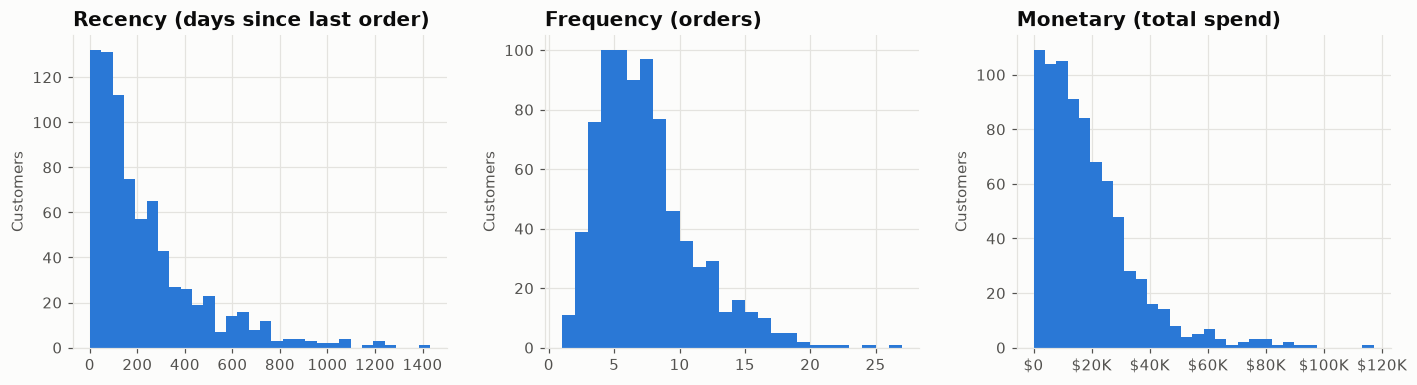

In [8]:
# Distribution of the raw R, F, M values
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(rfm["recency"], bins=30, color=vs.BLUE); axes[0].set_title("Recency (days since last order)")
axes[1].hist(rfm["frequency"], bins=range(1, rfm["frequency"].max() + 2), color=vs.BLUE)
axes[1].set_title("Frequency (orders)")
axes[2].hist(rfm["monetary"], bins=30, color=vs.BLUE); axes[2].set_title("Monetary (total spend)")
vs.money_axis(axes[2], "x")
for ax in axes: ax.set_ylabel("Customers")
fig.tight_layout(); vs.save(fig, "20_rfm_distributions.png"); plt.show()

## Step 5 · Segment-wise business actions

In [9]:
actions = {
    "High-Value (Champions)": "Reward with VIP/loyalty tier, early access to new products, ask for referrals; avoid unnecessary discounts.",
    "Loyal Customers": "Upsell higher-value Technology items, offer bundles and membership benefits to move them to Champions.",
    "Potential Loyalists": "Personalised recommendations, loyalty-programme enrolment, follow-up after each purchase.",
    "New Customers": "Onboarding communication, a time-limited second-purchase incentive, product guidance.",
    "Need Attention": "Targeted reminders and category-specific offers based on their past purchase.",
    "At-Risk Customers": "Win-back campaign: personal outreach, feedback survey, a carefully limited reactivation offer.",
    "Hibernating / Lost": "Low-cost automated re-engagement only; do not spend heavily; remove from expensive campaigns if no response.",
}
profile["recommended_action"] = profile.index.map(actions)
profile[["customers", "revenue_share_pct", "avg_recency_days", "avg_frequency", "avg_monetary", "recommended_action"]]

,customers,revenue_share_pct,avg_recency_days,avg_frequency,avg_monetary,recommended_action
segment,,,,,,
High-Value (Champions),127,32.83,55.02,12.01,"38,554.49","Reward with VIP/loyalty tier, early access to ..."
Loyal Customers,117,16.07,111.86,9.46,"20,483.81","Upsell higher-value Technology items, offer bu..."
Potential Loyalists,184,18.75,101.74,5.55,"15,196.73","Personalised recommendations, loyalty-programm..."
New Customers,5,0.51,139.00,2.60,"15,309.85","Onboarding communication, a time-limited secon..."
Need Attention,46,1.74,97.85,3.24,"5,651.40",Targeted reminders and category-specific offer...
At-Risk Customers,133,18.75,357.06,8.06,"21,028.96","Win-back campaign: personal outreach, feedback..."
Hibernating / Lost,183,11.35,516.09,3.44,"9,251.42",Low-cost automated re-engagement only; do not ...


## Step 6 · Cross-check: which customer business segments make up each RFM segment?
The dataset's own `segment` column (Corporate, Consumer and so on) describes the **type** of
customer. The RFM segment describes their **behaviour**. A customer can appear under more than
one business segment, so this table counts each customer's most common business segment.

In [10]:
main_bseg = df.groupby("customer_name")["segment"].agg(lambda s: s.mode().iloc[0])
rfm["main_business_segment"] = main_bseg
pd.crosstab(rfm["segment"], rfm["main_business_segment"], margins=True)

main_business_segment,Consumer,Corporate,Home Office,Small Business,All
segment,,,,,
High-Value (Champions),20,55,33,19,127
Loyal Customers,26,45,25,21,117
Potential Loyalists,41,62,44,37,184
New Customers,1,4,0,0,5
Need Attention,10,15,13,8,46
At-Risk Customers,30,45,31,27,133
Hibernating / Lost,36,62,47,38,183
All,164,288,193,150,795


## Step 7 · Save outputs

In [11]:
out = rfm.reset_index()
out["first_order"] = out["first_order"].dt.date
out["last_order"] = out["last_order"].dt.date
out.to_csv("../results/rfm_segments.csv", index=False)

champ = profile.loc["High-Value (Champions)"]
seg_metrics = {
    "reference_date": str(ref_date.date()),
    "n_customers": int(len(rfm)),
    "score_ranges": {f"{m} {b}": {str(s): int(v) for s, v in col.items()}
                     for (m, b), col in score_ranges.round(0).items()},
    "profile": profile.round(2).reset_index().astype({"segment": str}).to_dict("records"),
    "top2_revenue_share_pct": round(float(profile.loc[["High-Value (Champions)", "Loyal Customers"],
                                                      "revenue_share_pct"].sum()), 1),
    "top2_customer_share_pct": round(float(profile.loc[["High-Value (Champions)", "Loyal Customers"],
                                                       "customer_share_pct"].sum()), 1),
    "at_risk_revenue": round(float(profile.loc["At-Risk Customers", "total_revenue"]), 2),
}
with open("../results/rfm_metrics.json", "w") as f:
    json.dump(seg_metrics, f, indent=2, default=float)

print(f"Champions: {int(champ['customers'])} customers ({champ['customer_share_pct']:.1f}%) "
      f"generate {champ['revenue_share_pct']:.1f}% of revenue.")
print(f"Champions + Loyal: {seg_metrics['top2_customer_share_pct']}% of customers -> "
      f"{seg_metrics['top2_revenue_share_pct']}% of revenue.")
print(f"At-Risk customers represent ${seg_metrics['at_risk_revenue']:,.0f} of historical revenue to win back.")

Champions: 127 customers (16.0%) generate 32.8% of revenue.
Champions + Loyal: 30.7% of customers -> 48.9% of revenue.
At-Risk customers represent $2,796,852 of historical revenue to win back.


## Summary
* RFM divides customers into segments with simple rules that are easy to explain and act on.
* Most customers in this dataset are repeat buyers, so **Frequency** and **Recency** separate the
  strong customers from the slipping ones.
* The segment file (`results/rfm_segments.csv`) is loaded into the Power BI model, where the
  segment can be used as a slicer.

**Limitation.** Quintile scoring is *relative*. A score of 5 means "top 20% of *this* shop's
customers", not an absolute standard. Thresholds should be reviewed when new data arrives.